# 02 Customer-Level Feature Aggregation

The raw table is longitudinal, but the prediction target is defined once per customer. This notebook converts each customer's monthly history into a single row.

For continuous variables, it computes `mean`, `std`, `min`, `max`, and the chronological `last` value. For the 11 known categorical variables, it retains the chronological last value. 

It also keeps the final statement date as `S_2_last` and joins the customer target.

The result is a wide, customer-level Parquet table that can be split without placing one customer in both training and validation data.


In [1]:
from pathlib import Path

def find_project_root() -> Path:
    """Use the parent of the notebook working directory as the project root."""
    project_root = Path.cwd().resolve().parent
    if not (project_root / 'data').is_dir():
        raise FileNotFoundError(
            "Expected the project data directory one level above the current working directory."
        )
    return project_root

import time

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.ipc as ipc
import pyarrow.parquet as pq

pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')


### 1. Define inputs, outputs, and feature groups

The schema is separated into identifiers, date, categorical columns, and continuous columns.

In [ ]:
PROJECT_ROOT = find_project_root()
INPUT = PROJECT_ROOT / 'data' / 'train_data_float16_zstd.feather'
LABELS = PROJECT_ROOT / 'data' / 'train_labels.csv'
OUTPUT = PROJECT_ROOT / '02_aggregation' / 'train_aggregated.parquet'

CATEGORICAL_COLUMNS = [
    'B_30', 'B_38', 'D_114', 'D_116', 'D_117', 'D_120',
    'D_126', 'D_63', 'D_64', 'D_66', 'D_68'
]

with pa.memory_map(str(INPUT), 'r') as source:
    reader = ipc.open_file(source)
    source_columns = reader.schema.names
    number_of_batches = reader.num_record_batches

CONTINUOUS_COLUMNS = [
    column for column in source_columns
    if column not in {'customer_ID', 'S_2', *CATEGORICAL_COLUMNS}
]

print(f'Input columns：{len(source_columns)}')
print(f'Continuous variables：{len(CONTINUOUS_COLUMNS)} columns')
print(f'Categorical variables：{len(CATEGORICAL_COLUMNS)} columns')
print(f'Number of batches：{number_of_batches}')
print(f'Output file：{OUTPUT.resolve()}')


### 2. Align the label identifier

Labels retain the original hexadecimal customer ID, while the compressed statement data stores the final 64 bits as signed `int64`. The same conversion is applied before joining.

In [5]:
def compress_customer_id(series: pd.Series) -> np.ndarray:
    unsigned = np.fromiter(
        (int(customer_id[-16:], 16) for customer_id in series.astype(str)),
        dtype=np.uint64,
        count=len(series),
    )
    return unsigned.view(np.int64)

labels = pd.read_csv(LABELS)
assert labels['customer_ID'].is_unique, 'customer_ID should be unique in the label file'
labels['customer_ID'] = compress_customer_id(labels['customer_ID'])
assert labels['customer_ID'].is_unique, 'Conflicted Label customer_ID after compression'


### 3. Define aggregation for complete customers

Pandas summary statistics ignore missing values by default, which is appropriate for `mean`, `std`, `min`, and `max`. 

The chronological last value requires special handling. The code explicitly selects the final row after chronological ordering, preserving a missing last measurement when that is what the source data records.


In [6]:
def aggregate_complete_customers(frame: pd.DataFrame) -> pd.DataFrame:
    # Source records for each customer are contiguous and chronologically ordered.
    grouped = frame.groupby('customer_ID', sort=False, observed=True)

    numeric_stats = grouped[CONTINUOUS_COLUMNS].agg(['mean', 'std', 'min', 'max'])
    numeric_stats.columns = [
        f'{column}_{statistic}'
        for column, statistic in numeric_stats.columns
    ]

    last_rows = frame.drop_duplicates('customer_ID', keep='last').set_index('customer_ID')
    continuous_last = last_rows[CONTINUOUS_COLUMNS].rename(
        columns=lambda column: f'{column}_last'
    )
    categorical_last = last_rows[CATEGORICAL_COLUMNS].rename(
        columns=lambda column: f'{column}_last'
    )
    date_last = last_rows[['S_2']].rename(columns={'S_2': 'S_2_last'})

    result = numeric_stats.join(continuous_last).join(categorical_last).join(date_last)
    result = result.reset_index()

    numeric_output_columns = [
        column for column in result.columns
        if column not in {'customer_ID', 'S_2_last', *[f'{c}_last' for c in CATEGORICAL_COLUMNS]}
    ]
    result[numeric_output_columns] = result[numeric_output_columns].astype('float32')

    target = result['customer_ID'].map(target_by_customer)
    if target.isna().any():
        raise ValueError('Some customers do not have a matching target')
    result = pd.concat([result, target.rename('target').astype('int8')], axis=1)
    return result


### 4. Stream, aggregate, and write

Arrow batches do not guarantee that a customer ends exactly at a batch boundary. The last customer in each batch is therefore carried into the next batch before aggregation.


In [ ]:
writer = None
carry = None
written_customer_ids = set()
customers_written = 0
started = time.time()

try:
    with pa.memory_map(str(INPUT), 'r') as source:
        reader = ipc.open_file(source)

        for batch_index in range(reader.num_record_batches):
            frame = reader.get_batch(batch_index).to_pandas()
            if carry is not None:
                frame = pd.concat([carry, frame], ignore_index=True)

            date_order_ok = frame.groupby('customer_ID', sort=False)['S_2'].apply(
                lambda dates: dates.is_monotonic_increasing
            ).all()

            last_customer = frame['customer_ID'].iloc[-1]
            carry = frame.loc[frame['customer_ID'] == last_customer].copy()
            complete = frame.loc[frame['customer_ID'] != last_customer].copy()

            if len(complete):
                current_ids = set(complete['customer_ID'].unique())
                repeated = current_ids.intersection(written_customer_ids)

                aggregated = aggregate_complete_customers(complete)
                table = pa.Table.from_pandas(aggregated, preserve_index=False)

                if writer is None:
                    metadata = dict(table.schema.metadata or {})
                    metadata[b'aggregation'] = (
                        b'continuous=mean,std,min,max,last; categorical=last; date=last'
                    )
                    table = table.replace_schema_metadata(metadata)
                    writer = pq.ParquetWriter(
                        OUTPUT,
                        table.schema,
                        compression='zstd',
                        compression_level=6,
                        use_dictionary=True,
                    )

                writer.write_table(table)
                written_customer_ids.update(current_ids)
                customers_written += len(aggregated)

            elapsed = time.time() - started
            print(
                f'batch {batch_index + 1:>2}/{reader.num_record_batches}: '
            )

    if carry is not None and len(carry):
        assert carry['customer_ID'].nunique() == 1
        final_aggregated = aggregate_complete_customers(carry)
        final_table = pa.Table.from_pandas(final_aggregated, preserve_index=False)
        writer.write_table(final_table)
        written_customer_ids.add(int(carry['customer_ID'].iloc[0]))
        customers_written += 1
finally:
    if writer is not None:
        writer.close()

print(f'Aggregation completed: {customers_written:,} customers')


### 5. Validate the customer table

This step verifies the expected customer count, unique IDs, feature count, target completeness, label agreement, and absence of duplicated customers. It also checks the output schema and confirms that all input customers were emitted exactly once.


In [8]:
aggregated_file = pq.ParquetFile(OUTPUT)
expected_feature_columns = (
    len(CONTINUOUS_COLUMNS) * 5
    + len(CATEGORICAL_COLUMNS)
    + 1  # S_2_last
)
expected_total_columns = expected_feature_columns + 2  # customer_ID + target

# assert aggregated_file.metadata.num_rows == len(target_by_customer)
# assert aggregated_file.metadata.num_rows == customers_written
# assert aggregated_file.metadata.num_columns == expected_total_columns
# assert len(written_customer_ids) == customers_written

preview = aggregated_file.read_row_group(0).slice(0, 10).to_pandas()
assert preview['target'].notna().all()

print(f'Validation passed: {aggregated_file.metadata.num_rows:,} rows × {aggregated_file.metadata.num_columns:,} columns')
print(f'Feature columns: {expected_feature_columns:,} columns')
print(f'File size: {OUTPUT.stat().st_size / 2**30:.2f} GiB')
display(preview)


Validation passed: 458,913 rows × 899 columns
Feature columns: 897 columns
File size: 1.10 GiB


,customer_ID,P_2_mean,P_2_std,P_2_min,P_2_max,D_39_mean,D_39_std,D_39_min,D_39_max,B_1_mean,B_1_std,B_1_min,B_1_max,B_2_mean,B_2_std,...,D_144_last,D_145_last,B_30_last,B_38_last,D_114_last,D_116_last,D_117_last,D_120_last,D_126_last,D_63_last,D_64_last,D_66_last,D_68_last,S_2_last,target
0,-4532153018459703766,0.9338,0.0242,0.8687,0.9604,0.0107,0.0244,0.0011,0.0915,0.0120,0.0065,0.0019,0.0217,1.0052,0.0032,...,0.0030,0.0085,0,2,1,0,4,0,1,2,1,<NA>,6,2018-03-13,0
1,-6696652885210834715,0.8998,0.0221,0.8613,0.9292,0.2152,0.1991,0.0022,0.5674,0.0257,0.0278,0.0067,0.1096,0.9911,0.0515,...,0.0032,0.0085,0,2,1,0,-1,0,1,1,1,<NA>,6,2018-03-25,0
2,7128959966677571777,0.8784,0.0288,0.7979,0.9043,0.0042,0.0028,0.0008,0.0097,0.0044,0.0028,0.0015,0.0100,0.8157,0.0035,...,0.0008,0.0034,0,1,1,0,-1,0,1,1,2,<NA>,6,2018-03-12,0
3,6537921148391624412,0.5989,0.0201,0.5674,0.6235,0.0489,0.0885,0.0007,0.2686,0.0599,0.0805,0.0059,0.2800,0.9551,0.0809,...,0.0056,0.0030,0,2,1,0,6,0,1,1,1,<NA>,3,2018-03-29,0
4,2065103583825424365,0.8918,0.0423,0.8052,0.9404,0.0046,0.0029,0.0000,0.0087,0.0059,0.0025,0.0008,0.0098,0.8146,0.0031,...,0.0069,0.0009,0,1,1,0,4,0,1,1,1,1,6,2018-03-30,0
5,5835591494914154540,0.7941,0.0192,0.7651,0.8242,0.1993,0.2386,0.0071,0.7119,0.0271,0.0147,0.0079,0.0516,0.9748,0.0710,...,0.0069,0.0014,0,2,1,0,1,0,1,1,2,<NA>,6,2018-03-19,0
6,-465261335499253548,0.4446,0.0651,0.3291,0.5605,0.0104,0.0147,0.0005,0.0386,0.0708,0.0315,0.0094,0.1126,0.2478,0.3449,...,0.0037,0.0063,0,3,0,0,2,0,0,1,2,<NA>,3,2018-03-12,0
7,-7255018874980310143,1.0059,0.0034,1.0000,1.0098,0.3535,0.2151,0.0008,0.5610,0.0630,0.0364,-0.0009,0.1021,0.2339,0.2467,...,0.0033,0.0007,0,3,1,0,6,0,1,1,2,<NA>,5,2018-03-23,0
8,6642993746178481797,0.4067,0.0091,0.3916,0.4246,0.1247,0.2096,0.0003,0.6475,0.9386,0.0233,0.9126,0.9824,0.0254,0.0027,...,0.0033,0.7344,1,7,0,0,-1,0,1,1,3,1,6,2018-03-01,1
9,7187171820285796022,0.4473,0.0587,0.3599,0.5562,0.0065,0.0033,0.0000,0.0099,0.0170,0.0265,0.0002,0.0907,0.8161,0.0028,...,0.0071,0.0063,0,1,0,0,4,0,1,1,1,<NA>,5,2018-03-16,1


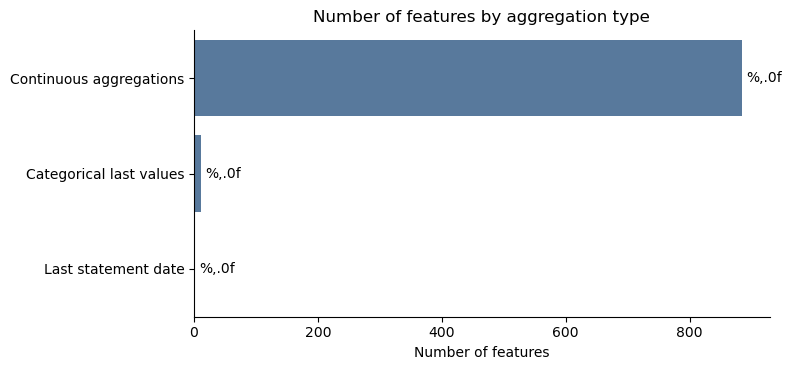

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Composition of the customer-level feature table
feature_composition = pd.DataFrame({
    'feature_group': ['Continuous aggregations', 'Categorical last values', 'Last statement date'],
    'features': [len(CONTINUOUS_COLUMNS) * 5, len(CATEGORICAL_COLUMNS), 1],
})
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.barplot(data=feature_composition, y='feature_group', x='features', color='#4C78A8', ax=ax)
ax.set(title='Number of features by aggregation type', xlabel='Number of features', ylabel='')
ax.bar_label(ax.containers[0], fmt='%,.0f', padding=3)
sns.despine()
plt.tight_layout()
plt.show()
